# Yambda-50M: разведочный анализ под задачу ранжирования

Цель ноутбука: понять данные настолько, чтобы осмысленно придумывать признаки и не наделать утечек.
Каждый раздел заканчивается блоком **"Что это значит для задачи"**. В нём сказано, какие признаки отсюда следуют и где подвох.

План:
1. Что лежит в данных и что означает каждая колонка
2. Типы событий
3. Время: сколько дней, суточный ритм
4. Пользователи
5. Треки и длинный хвост популярности
6. `played_ratio_pct` и определение целевой переменной
7. Длина трека как источник смещения
8. Повторное потребление: прямые и косвенные связи
9. Сколько времени проходит до повтора (откуда берутся окна 1/7/30 дней)
10. Сессии и короткая память
11. Лайки и дизлайки
12. Артисты и альбомы
13. Репетиция тестового дня: что должна покрыть генерация кандидатов
14. Окно против затухания: иллюстрация к нашей идее
15. Итог: карта признаков
16. Постановка A и разбиение на train / val / test

### Подготовка (один раз, из корня `recsys_task`)

```
python3 scripts/download_yambda.py
python3 scripts/prepare_listens.py
```

Первый скрипт скачивает около 460 MB. Второй за пару минут считает тяжёлые построчные колонки: номер повтора, интервал до прошлого прослушивания, сессии. Обработка идёт кусками по 1000 пользователей, пик памяти около 2 GB. Результат пишется в `data/yambda/derived/50m/listens/*.parquet`.

### Как ноутбук бережёт память

Полную таблицу в память он **не загружает**. Каждая ячейка лениво читает только нужные колонки (`pl.scan_parquet(...).select(...)`), агрегирует в потоковом режиме (`collect(engine="streaming")`) и получает маленькую таблицу. Гистограммы строятся по заранее посчитанным корзинам, а не по сырым массивам. В ключевых ячейках печатается текущее потребление памяти процессом.

В первой ячейке до импорта polars выставлены две переменные окружения:
- `_RJEM_MALLOC_CONF` заставляет аллокатор polars (jemalloc) возвращать освободившуюся память системе. Без неё процесс держит пиковую память до конца работы ядра: на этом ноутбуке это около 5 GB против примерно 1 GB с настройкой;
- `POLARS_MAX_THREADS=4` ограничивает число потоков и вместе с ними размер буферов.

Если ядро уже запускалось, его нужно перезапустить, иначе переменные не подействуют.

In [1]:
import os

os.environ["_RJEM_MALLOC_CONF"] = "background_thread:true,dirty_decay_ms:500,muzzy_decay_ms:500"
os.environ["POLARS_MAX_THREADS"] = "4"

import gc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import psutil

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(20)
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})

DATA = Path("../data/yambda")
EVENTS_PATH = DATA / "flat/50m/multi_event.parquet"
LISTENS_PATH = DATA / "derived/50m/listens/*.parquet"
if not EVENTS_PATH.exists() or not list((DATA / "derived/50m/listens").glob("*.parquet")):
    raise FileNotFoundError("run scripts/download_yambda.py and scripts/prepare_listens.py first")

DAY = 86400
HOUR = 3600


def events(*cols):
    lf = pl.scan_parquet(EVENTS_PATH)
    return lf.select(cols) if cols else lf


def listens(*cols):
    lf = pl.scan_parquet(LISTENS_PATH)
    return lf.select(cols) if cols else lf


def run(lf):
    return lf.collect(engine="streaming")


def rss():
    gc.collect()
    print(f"process memory: {psutil.Process(os.getpid()).memory_info().rss / 2**30:.2f} GB")


rss()

process memory: 0.12 GB


## 1. Что лежит в данных

Используем три исходных файла:
- `flat/50m/multi_event.parquet` содержит все события всех типов в одной таблице, отсортированные по `(uid, timestamp)`;
- `artist_item_mapping.parquet` задаёт соответствие трек -> артист;
- `album_item_mapping.parquet` задаёт соответствие трек -> альбом.

Файл `embeddings.parquet` с аудиоэмбеддингами весит 13.8 GB, пока его не качаем.

In [2]:
print(pl.scan_parquet(EVENTS_PATH).collect_schema())
pl.scan_parquet(EVENTS_PATH).head(10).collect()

Schema({'uid': UInt32, 'timestamp': UInt32, 'item_id': UInt32, 'is_organic': UInt8, 'played_ratio_pct': UInt16, 'track_length_seconds': UInt32, 'event_type': Enum(categories=['listen', 'dislike', 'like', 'undislike', 'unlike'])})


uid,timestamp,item_id,is_organic,played_ratio_pct,track_length_seconds,event_type
u32,u32,u32,u8,u16,u32,enum
100,39420,8326270,0,100,170,"""listen"""
100,39420,1441281,0,100,105,"""listen"""
100,39625,286361,0,100,185,"""listen"""
100,40110,732449,0,100,240,"""listen"""
100,40360,3397170,0,46,130,"""listen"""
100,40380,7849270,0,100,205,"""listen"""
100,40640,1449307,0,100,205,"""listen"""
100,40785,6887232,0,100,145,"""listen"""
100,40885,2996197,0,100,95,"""listen"""


| Колонка | Тип | Что означает | Зачем нам |
|---|---|---|---|
| `uid` | uint32 | id пользователя | ключ для всех пользовательских признаков |
| `item_id` | uint32 | id трека | ключ для признаков трека и пары |
| `timestamp` | uint32 | секунды от начала датасета, округлены до 5 с. **У прослушивания это момент его конца**: интервал до следующего события почти равен длительности следующего прослушивания | сплит по времени, окна, давность. Абсолютной даты нет. Для признаков момент запроса - конец предыдущего прослушивания, иначе утечка (`BASELINE.md`, раздел 2) |
| `is_organic` | 0/1 | 1: пользователь сам нашёл трек (поиск, свой плейлист, альбом). 0: трек поставил рекомендатель ("Моя волна", персональные плейлисты) | рекомендательные прослушивания похожи на показы. Это кандидат на честную постановку "показ -> отклик" |
| `played_ratio_pct` | uint16 | какой процент трека проигран (бывает больше 100, если перематывали назад) | отсюда берётся целевая переменная Listen+ и сигнал "скип" |
| `track_length_seconds` | uint32 | длина трека в секундах | признак трека и источник смещения (раздел 7) |
| `event_type` | enum | `listen`, `like`, `dislike`, `unlike` (снял лайк), `undislike` (снял дизлайк) | явная обратная связь |

`played_ratio_pct` и `track_length_seconds` заполнены только у `listen`.

Колонки, которые добавил `prepare_listens.py`:

| Колонка | Что означает |
|---|---|
| `artist_id`, `album_id` | артист и альбом трека (если их несколько, берём первый) |
| `listen_plus` | `played_ratio_pct >= 50`, целевая переменная |
| `track_seen_n` | сколько раз пользователь слушал этот трек **до** этого события |
| `artist_seen_n` | то же для артиста |
| `dt_track`, `dt_artist` | секунд с прошлого прослушивания этого трека или артиста этим пользователем |
| `session_idx`, `pos_in_session` | номер сессии пользователя (сессия рвётся при паузе больше 30 минут) и позиция в ней |
| `prev_listen_plus` | дослушан ли предыдущий трек этой сессии |

Все эти колонки смотрят только в прошлое пользователя, поэтому их можно использовать как признаки без утечки.

In [3]:
run(events("uid", "item_id", "timestamp").select(
    pl.col("uid").n_unique().alias("users_any_event"),
    pl.col("item_id").n_unique().alias("items"),
    pl.len().alias("events"),
    (pl.col("timestamp").max() / DAY).alias("days"),
)).hstack(run(listens("uid").select(pl.col("uid").n_unique().alias("users_with_listens"))))

users_any_event,items,events,days,users_with_listens
u32,u32,u32,f64,u32
10000,934057,47790449,300.925926,9238


## 2. Типы событий

In [4]:
run(
    events("event_type", "is_organic", "uid")
    .group_by("event_type")
    .agg(pl.len().alias("n"), pl.col("uid").n_unique().alias("users"), pl.col("is_organic").mean().alias("organic_share"))
).with_columns((pl.col("n") / pl.col("n").sum()).alias("share")).sort("n", descending=True)

event_type,n,users,organic_share,share
enum,u32,u32,f64,f64
"""listen""",46467212,9238,0.516572,0.972312
"""like""",881456,8283,0.56974,0.018444
"""unlike""",312972,6406,0.947181,0.006549
"""dislike""",107776,5951,0.519485,0.002255
"""undislike""",21033,2911,0.889507,0.00044


**Что это значит для задачи**
- 97% событий составляют прослушивания. Лайков меньше 2%, а дизлайков в 8 раз меньше, чем лайков. Явная обратная связь редкая, основной сигнал неявный: дослушал пользователь трек или нет.
- Около половины прослушиваний пришло из рекомендаций (`is_organic = 0`). Сервис сам активно формирует историю. Поэтому признаки вида "сколько раз слушал" отчасти измеряют прошлую рекомендательную политику, а не только вкус.
- `unlike` почти всегда органический: пользователь заходит в "Мне нравится" и чистит список.
- Прослушивания есть у 9 238 пользователей из 10 000. У остальных в истории только лайки и дизлайки.

## 3. Время

Датасет покрывает около 300 дней. Даты сдвинуты, поэтому день недели и праздники неизвестны.

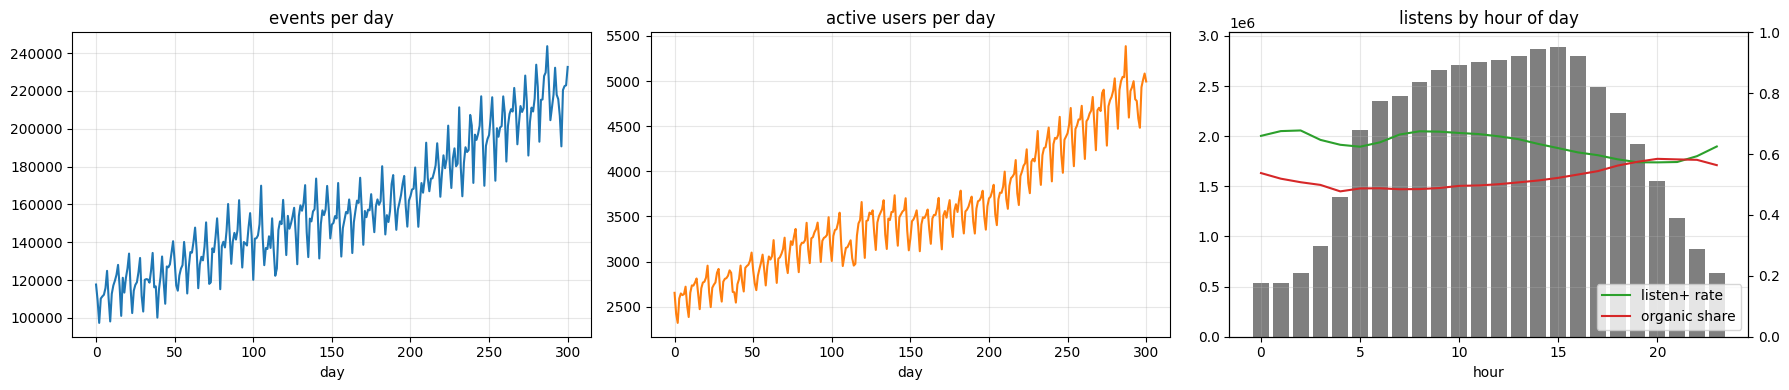

process memory: 0.16 GB


In [5]:
daily = run(
    events("timestamp", "uid")
    .group_by((pl.col("timestamp") // DAY).alias("day"))
    .agg(pl.len().alias("events"), pl.col("uid").n_unique().alias("active_users"))
).sort("day")
hourly = run(
    listens("timestamp", "listen_plus", "is_organic")
    .group_by(((pl.col("timestamp") % DAY) // HOUR).alias("hour"))
    .agg(pl.len().alias("n"), pl.col("listen_plus").mean().alias("listen_plus_rate"), pl.col("is_organic").mean().alias("organic_share"))
).sort("hour")

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(daily["day"], daily["events"])
ax[0].set_title("events per day")
ax[0].set_xlabel("day")
ax[1].plot(daily["day"], daily["active_users"], color="tab:orange")
ax[1].set_title("active users per day")
ax[1].set_xlabel("day")
ax[2].bar(hourly["hour"], hourly["n"], color="tab:gray")
ax[2].set_title("listens by hour of day")
ax[2].set_xlabel("hour")
ax2 = ax[2].twinx()
ax2.plot(hourly["hour"], hourly["listen_plus_rate"], color="tab:green", label="listen+ rate")
ax2.plot(hourly["hour"], hourly["organic_share"], color="tab:red", label="organic share")
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right")
ax2.grid(False)
plt.tight_layout()
plt.show()
rss()

**Что это значит для задачи**
- По суточному ритму видно, что ноль шкалы близок к полуночи: минимум активности приходится на часы 0-2. Значит, час суток можно использовать как признак контекста, он известен в момент запроса.
- Активность растёт к концу периода. Популярность нужно считать по свежему окну, а не за всю историю.
- Каждый день активна только часть пользователей.
- Сплит делаем глобальный по времени, как в статье Yambda: последний день идёт в тест, предпоследний в валидацию, перед каждым зазор 30 минут. Случайный сплит или leave-one-out здесь дадут утечку из будущего.

## 4. Пользователи

statistic,listens,unique_tracks,active_days,organic_share,listen_plus_rate
str,f64,f64,f64,f64,f64
"""count""",9238.0,9238.0,9238.0,9238.0,9238.0
"""null_count""",0.0,0.0,0.0,0.0,0.0
"""mean""",5030.007794,1436.337844,111.568088,0.540478,0.623509
"""std""",5520.14541,1292.95917,85.69797,0.309514,0.227304
"""min""",6.0,2.0,1.0,0.0,0.0
"""25%""",937.0,478.0,35.0,0.292699,0.465517
"""50%""",3024.0,1087.0,92.0,0.542964,0.644829
"""75%""",7182.0,2024.0,181.0,0.81305,0.806167
"""max""",27617.0,9843.0,301.0,1.0,1.0


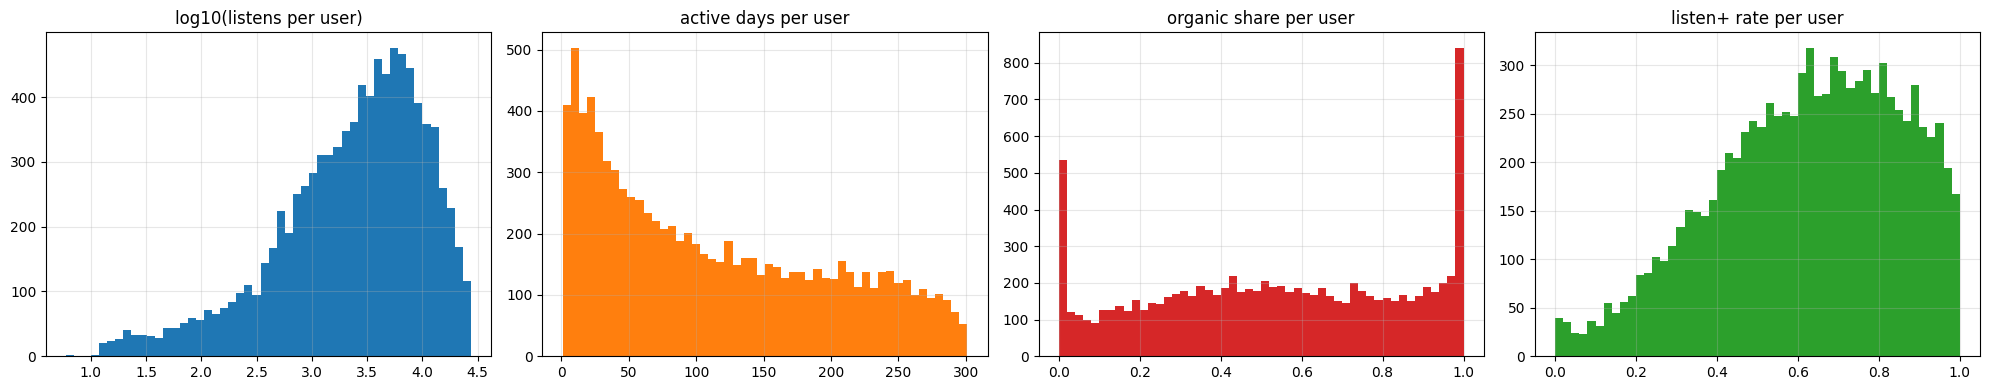

process memory: 0.18 GB


In [6]:
users = run(
    listens("uid", "item_id", "timestamp", "is_organic", "listen_plus")
    .group_by("uid")
    .agg(
        pl.len().alias("listens"),
        pl.col("item_id").n_unique().alias("unique_tracks"),
        (pl.col("timestamp") // DAY).n_unique().alias("active_days"),
        pl.col("is_organic").mean().alias("organic_share"),
        pl.col("listen_plus").mean().alias("listen_plus_rate"),
    )
)
display(users.drop("uid").describe())

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].hist(np.log10(users["listens"]), bins=50)
ax[0].set_title("log10(listens per user)")
ax[1].hist(users["active_days"], bins=50, color="tab:orange")
ax[1].set_title("active days per user")
ax[2].hist(users["organic_share"], bins=50, color="tab:red")
ax[2].set_title("organic share per user")
ax[3].hist(users["listen_plus_rate"], bins=50, color="tab:green")
ax[3].set_title("listen+ rate per user")
plt.tight_layout()
plt.show()
rss()

**Что это значит для задачи**
- История длинная: в среднем тысячи прослушиваний на пользователя, у самых активных больше 20 000. Подать всю историю в трансформер не получится. Это и есть вопрос масштаба из третьего направления.
- Пользователи сильно различаются по активности, разброс на три порядка. Абсолютные счётчики стоит дополнять нормированными: доля от всех прослушиваний пользователя, ранг, логарифм.
- `organic_share` распределён от 0 до 1. Есть пользователи, которые живут в "Моей волне", и те, кто слушает только своё. Это сильный признак пользователя: он показывает, насколько человек вообще открыт новому.
- `listen_plus_rate` пользователя показывает базовую склонность дослушивать. Это главный пользовательский признак для предсказания Listen+.

## 5. Треки и длинный хвост

items with listens: 877,168
items with a single listener: 49.9%
top 1% items -> 49.2% of listens
top 10% items -> 87.9% of listens


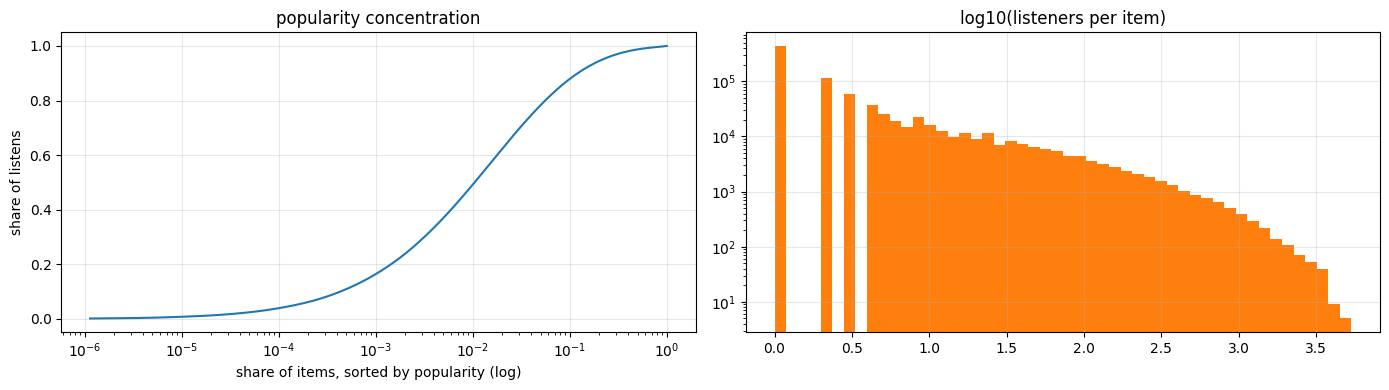

process memory: 0.30 GB


In [7]:
items = run(
    listens("item_id", "uid", "listen_plus", "track_length_seconds")
    .group_by("item_id")
    .agg(
        pl.len().alias("listens"),
        pl.col("uid").n_unique().alias("users"),
        pl.col("listen_plus").mean().alias("listen_plus_rate"),
    )
)
sorted_counts = np.sort(items["listens"].to_numpy())[::-1]
cum_share = np.cumsum(sorted_counts) / sorted_counts.sum()
n = len(sorted_counts)
print(f"items with listens: {n:,}")
print(f"items with a single listener: {(items['users'] == 1).mean():.1%}")
print(f"top 1% items -> {cum_share[int(n * 0.01)]:.1%} of listens")
print(f"top 10% items -> {cum_share[int(n * 0.10)]:.1%} of listens")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(np.arange(1, n + 1) / n, cum_share)
ax[0].set_xscale("log")
ax[0].set_xlabel("share of items, sorted by popularity (log)")
ax[0].set_ylabel("share of listens")
ax[0].set_title("popularity concentration")
ax[1].hist(np.log10(items["users"]), bins=50, color="tab:orange")
ax[1].set_yscale("log")
ax[1].set_title("log10(listeners per item)")
plt.tight_layout()
plt.show()
del sorted_counts, cum_share
rss()

**Что это значит для задачи**
- Очень длинный хвост: половину треков слушал ровно один человек, а 1% треков собирает около половины прослушиваний.
- Признаки трека (популярность, доля дослушиваний) надёжны только для головы распределения. Для хвоста статистики шумные. Их нужно сглаживать к среднему (байесовское среднее) или поднимать на уровень артиста и альбома.
- MostPop будет сильным, но очень узким бейзлайном: в статье Yambda его coverage около 0.

## 6. `played_ratio_pct` и целевая переменная

Главный вопрос раздела: логируются ли скипы? Если пользователь пропустил трек из "Моей волны" через 3 секунды, появится ли такая строка в данных?

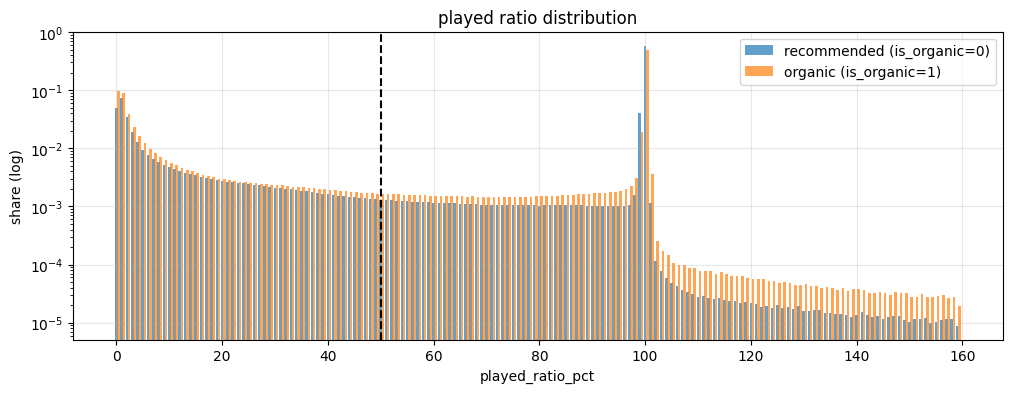

bucket,organic,recommended
cat,f64,f64
"""0-5""",0.274644,0.198676
"""100+""",0.490073,0.587116
"""11-30""",0.063044,0.058065
"""31-49""",0.036947,0.031421
"""50-80""",0.04709,0.035257
"""6-10""",0.037049,0.029953
"""81-99""",0.051153,0.059511


is_organic,n,listen_plus_rate,skip_rate_le5
u8,u32,f64,f64
0,22463555,0.681884,0.198676
1,24003657,0.588316,0.274644


In [8]:
ratio = run(
    listens("played_ratio_pct", "is_organic")
    .group_by("is_organic", pl.col("played_ratio_pct").clip(0, 160).alias("pct"))
    .agg(pl.len().alias("n"))
).with_columns((pl.col("n") / pl.col("n").sum().over("is_organic")).alias("share")).sort("pct")

fig, ax = plt.subplots(figsize=(12, 4))
for flag, name in [(0, "recommended (is_organic=0)"), (1, "organic (is_organic=1)")]:
    part = ratio.filter(pl.col("is_organic") == flag)
    ax.bar(part["pct"] + (0.4 if flag else 0), part["share"], width=0.5, alpha=0.7, label=name)
ax.set_yscale("log")
ax.axvline(50, color="black", linestyle="--")
ax.set_xlabel("played_ratio_pct")
ax.set_ylabel("share (log)")
ax.set_title("played ratio distribution")
ax.legend()
plt.show()

buckets = (
    ratio.with_columns(
        pl.col("pct").cut([5, 10, 30, 49, 80, 99], labels=["0-5", "6-10", "11-30", "31-49", "50-80", "81-99", "100+"]).alias("bucket")
    )
    .group_by("bucket", "is_organic").agg(pl.col("share").sum())
    .pivot(on="is_organic", index="bucket", values="share")
    .rename({"0": "recommended", "1": "organic"})
    .sort("bucket")
)
display(buckets)
run(listens("is_organic", "listen_plus", "played_ratio_pct").group_by("is_organic").agg(
    pl.len().alias("n"),
    pl.col("listen_plus").mean().alias("listen_plus_rate"),
    (pl.col("played_ratio_pct") <= 5).mean().alias("skip_rate_le5"),
)).sort("is_organic")

**Что это значит для задачи**
- Распределение бимодальное. Около 50-60% прослушиваний доиграны до конца, 20-27% скипнуты в первые 5%, а на весь диапазон 11-49% приходится около 10%. Значит, **скипы логируются**, и порог 50% разделяет два естественных режима. Конкретное значение порога почти не важно.
- У рекомендательных прослушиваний есть отдельный пик на 99%. Вероятно, это кроссфейд: лента переключается на следующий трек за секунду до конца. Для порога 50% это не важно, но ровно `== 100` как определение "дослушал" использовать нельзя.
- Отсюда честная постановка для рекомендательного прослушивания (`is_organic = 0`): трек поставил алгоритм, пользователь его либо дослушал (позитив), либо скипнул (настоящий негатив). Сэмплировать негативы не нужно.
- Интересно, что органические прослушивания скипают **чаще** рекомендательных: 27% против 20%, а Listen+ у них 59% против 68%. Похоже, это листание своего плейлиста или альбома в поисках нужного трека. Органический скип означает другое, поэтому `is_organic` стоит держать в признаках отдельно.
- Определение: **Listen+ = `played_ratio_pct >= 50`**. В карточке датасета написано "более 50%". На бимодальном распределении разница в одну точку почти ничего не меняет, но в отчёте это нужно зафиксировать.

## 7. Длина трека как источник смещения

In [9]:
run(
    listens("track_length_seconds", "listen_plus", "played_ratio_pct")
    .group_by(pl.col("track_length_seconds").cut([120, 180, 240, 300, 420]).alias("length_bucket"))
    .agg(
        pl.len().alias("n"),
        pl.col("listen_plus").mean().alias("listen_plus_rate"),
        (pl.col("played_ratio_pct") <= 5).mean().alias("skip_rate"),
    )
).sort("length_bucket")

length_bucket,n,listen_plus_rate,skip_rate
cat,u32,f64,f64
"""(-inf, 120]""",2329419,0.68237,0.172388
"""(120, 180]""",14686078,0.660822,0.210963
"""(180, 240]""",20201274,0.62829,0.246786
"""(240, 300]""",6583002,0.599387,0.270743
"""(300, 420]""",2171029,0.572979,0.288872
"""(420, inf]""",496410,0.529599,0.323964


**Что это значит для задачи**
- Чем короче трек, тем выше доля дослушиваний: дослушать короткий трек просто легче.
- Длина трека - законный и полезный признак. Но модель, которая оптимизирует Listen+, будет систематически поднимать короткие треки. Для задачи `recsys_rl` это прямой пример reward hacking из задания ("модель может начать предпочитать короткие объекты").

## 8. Повторное потребление: прямые и косвенные связи

Для каждого прослушивания определяем, что пользователь уже знал на этот момент:
- `repeat_track`: этот трек он уже слушал (прямая связь);
- `new_track_known_artist`: трек новый, но этого артиста он уже слушал (косвенная связь);
- `new_artist`: незнакомый артист, то есть настоящее открытие.

novelty,n,listen_plus_rate,organic_share,share
str,u32,f64,f64,f64
"""repeat_track""",33198323,0.646142,0.58308,0.714446
"""new_track_known_artist""",7512520,0.625705,0.361326,0.161674
"""new_artist""",5756369,0.571165,0.335611,0.12388


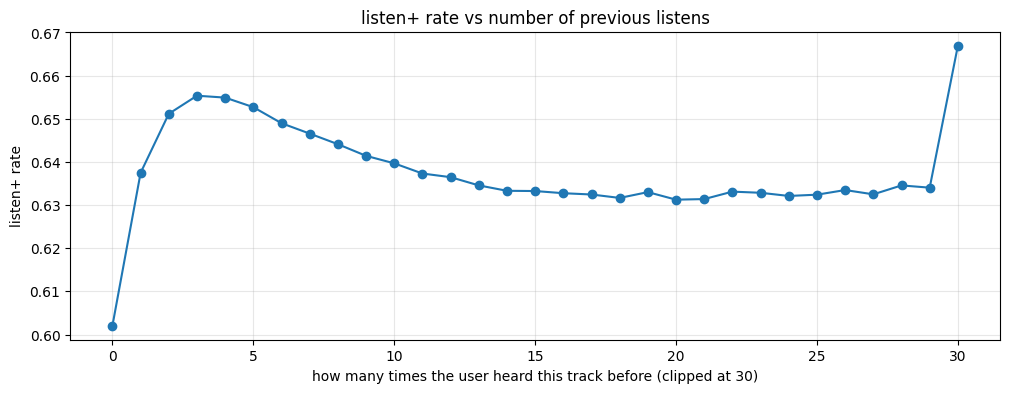

process memory: 0.26 GB


In [10]:
novelty = (
    pl.when(pl.col("track_seen_n") > 0).then(pl.lit("repeat_track"))
    .when(pl.col("artist_seen_n") > 0).then(pl.lit("new_track_known_artist"))
    .otherwise(pl.lit("new_artist"))
    .alias("novelty")
)
display(
    run(
        listens("track_seen_n", "artist_seen_n", "listen_plus", "is_organic")
        .group_by(novelty)
        .agg(pl.len().alias("n"), pl.col("listen_plus").mean().alias("listen_plus_rate"), pl.col("is_organic").mean().alias("organic_share"))
    ).with_columns((pl.col("n") / pl.col("n").sum()).alias("share")).sort("n", descending=True)
)

by_count = run(
    listens("track_seen_n", "listen_plus")
    .group_by(pl.col("track_seen_n").clip(0, 30).alias("times_heard_before"))
    .agg(pl.len().alias("n"), pl.col("listen_plus").mean().alias("listen_plus_rate"))
).sort("times_heard_before")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(by_count["times_heard_before"], by_count["listen_plus_rate"], marker="o")
ax.set_xlabel("how many times the user heard this track before (clipped at 30)")
ax.set_ylabel("listen+ rate")
ax.set_title("listen+ rate vs number of previous listens")
plt.show()
rss()

**Что это значит для задачи**
- **71% прослушиваний составляют повторы.** Музыка - домен повторного потребления, и это главный факт всего датасета. Признак "сколько раз пользователь слушал этот трек" будет самым сильным, и любая модель без него проиграет.
- Ещё около 16% приходится на новые треки знакомых артистов. Здесь работают косвенные признаки: сколько раз пользователь слушал артиста или альбом, как часто его дослушивал.
- Настоящих открытий только около 12%. Для них помогают лишь коллаборативные сигналы (похожие пользователи, ItemKNN) и контент (аудиоэмбеддинги).
- Открытия в основном приходят из рекомендаций: органических среди них около 35%, против 58% у повторов.
- По графику видно, что зависимость немонотонная. Новый трек дослушивают в 60% случаев, к 3-4 прослушиваниям доля растёт до 65.5%, а дальше медленно падает до 63%: трек приедается. Бустинг такую форму поймает сам. Для линейных моделей и нейросетей лучше подавать `log1p(count)` и давность, а не одно сырое число.
- Метрики в отчёте нужно **разбивать по этим трём группам**. Модель, которая хороша только на повторах, по сути выучила один признак.

## 9. Сколько времени проходит до повтора

Задание спрашивает: почему окно 7 дней, а не 10? Посмотрим, через сколько времени пользователь возвращается к треку и к артисту.

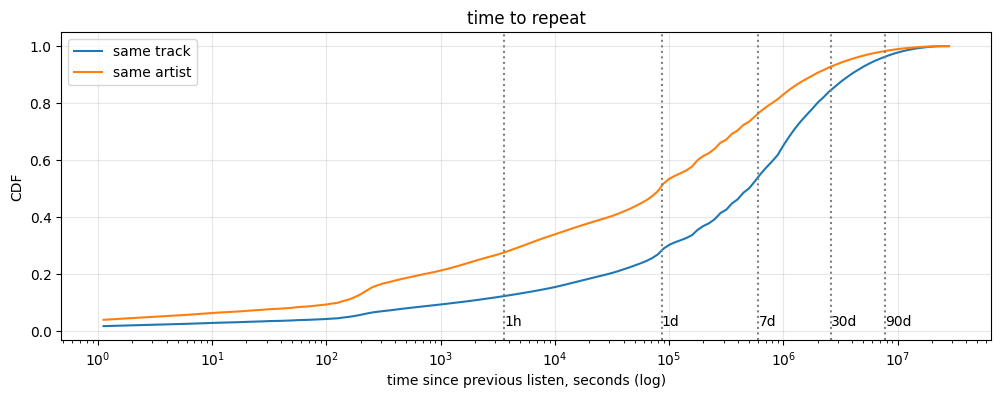

track<=1h,track<=1d,track<=7d,track<=30d,track<=90d,artist<=1h,artist<=1d,artist<=7d,artist<=30d,artist<=90d
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.123122,0.282954,0.540496,0.84507,0.962908,0.27618,0.509534,0.76386,0.927703,0.982812


In [11]:
def gap_cdf(col):
    hist = run(
        listens(col).drop_nulls()
        .group_by((pl.col(col).cast(pl.Float64) + 1).log10().mul(20).floor().alias("bin"))
        .agg(pl.len().alias("n"))
    ).sort("bin")
    return 10 ** ((hist["bin"].to_numpy() + 1) / 20), np.cumsum(hist["n"].to_numpy()) / hist["n"].sum()


marks = {"1h": HOUR, "1d": DAY, "7d": 7 * DAY, "30d": 30 * DAY, "90d": 90 * DAY}
fig, ax = plt.subplots(figsize=(12, 4))
for col, name in [("dt_track", "same track"), ("dt_artist", "same artist")]:
    x, y = gap_cdf(col)
    ax.plot(x, y, label=name)
for label, seconds in marks.items():
    ax.axvline(seconds, color="gray", linestyle=":")
    ax.text(seconds, 0.02, label)
ax.set_xscale("log")
ax.set_xlabel("time since previous listen, seconds (log)")
ax.set_ylabel("CDF")
ax.set_title("time to repeat")
ax.legend()
plt.show()

run(listens("dt_track", "dt_artist").select(
    [(pl.col(c).drop_nulls() <= v).mean().alias(f"{c[3:]}<={k}") for c in ["dt_track", "dt_artist"] for k, v in marks.items()]
))

In [12]:
run(
    listens("dt_track", "listen_plus").drop_nulls("dt_track")
    .group_by(
        pl.col("dt_track").cut([HOUR, 6 * HOUR, DAY, 3 * DAY, 7 * DAY, 30 * DAY, 90 * DAY],
                               labels=["<1h", "1-6h", "6h-1d", "1-3d", "3-7d", "7-30d", "30-90d", ">90d"]).alias("since_last_listen")
    )
    .agg(pl.len().alias("n"), pl.col("listen_plus").mean().alias("listen_plus_rate"))
).sort("since_last_listen")

since_last_listen,n,listen_plus_rate
cat,u32,f64
"""1-3d""",3892952,0.649466
"""1-6h""",2137138,0.688567
"""3-7d""",4657026,0.654543
"""30-90d""",3912034,0.648834
"""6h-1d""",3168999,0.665191
"""7-30d""",10111346,0.668397
"""<1h""",4087450,0.541944
""">90d""",1231378,0.635781


**Что это значит для задачи**
- Время до повтора растянуто на много порядков. Из повторов трека 12% случаются в пределах часа, 28% в пределах суток, 54% в пределах недели, 85% в пределах месяца. У артиста шкала короче: 28% / 51% / 76% / 93%. Естественного масштаба "7 дней" нет, и любое одно окно теряет информацию. Поэтому люди и строят набор окон 1/7/30/90.
- На кривой видны ступеньки ровно на 1, 2, 3 днях: люди слушают в одно и то же время суток (дорога на работу, спортзал). Отсюда признаки "слушал ли этот трек или артиста вчера в это же время" и разница текущего часа с привычным часом пользователя.
- Давность прошлого прослушивания влияет на вероятность дослушать, причём немонотонно. Если трек звучал меньше часа назад, его дослушивают только в 54% случаев: только что слышал, и рекомендатель или шаффл подсунул его снова. Через 1-6 часов доля максимальна (69%), дальше выходит на плато около 65%. Признак "сколько прошло с последнего прослушивания" (recency) нужен в дополнение к счётчикам.
- Для нашей идеи это важное наблюдение: один счётчик с затуханием этот провал не поймает, ведь он просто больше для недавних событий. Нужны как минимум два масштаба `tau`, короткий и длинный, и модель сверху, которая умеет их вычитать.
- Отсюда прямая мотивация нашей идеи: заменить набор окон на счётчики с затуханием `exp(-dt / tau)` и подбирать `tau` градиентом. Иллюстрация в разделе 14.

## 10. Сессии и короткая память

Сессией считаем прослушивания без перерыва больше 30 минут.

sessions: 2,452,609, median length: 10, mean: 18.9


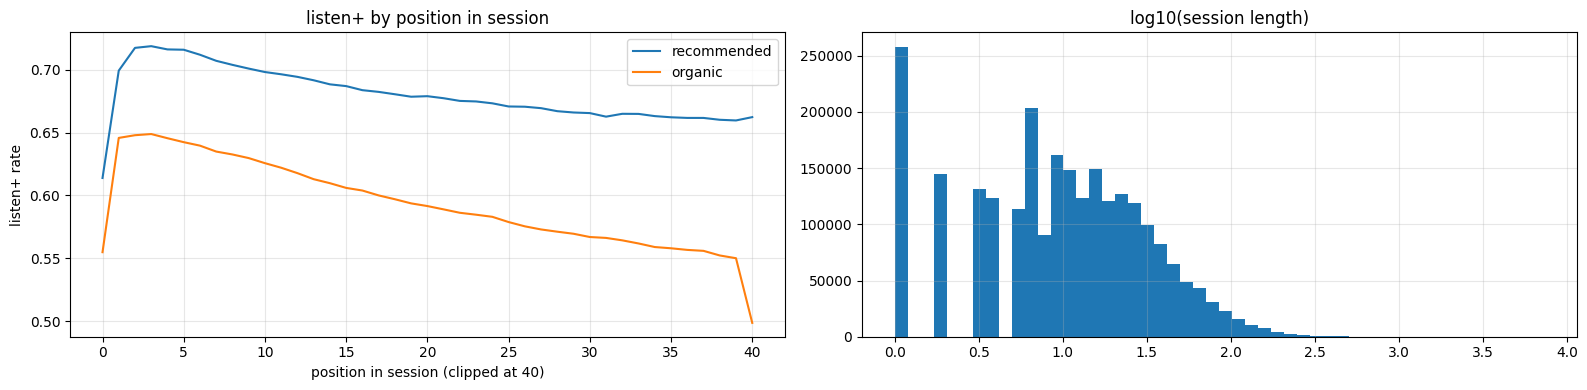

is_organic,prev_listen_plus,n,listen_plus_rate
u8,bool,u32,f64
0,false,6730041,0.265681
0,true,14652133,0.878075
1,false,9553451,0.301074
1,true,13078978,0.801633


In [13]:
sessions = run(
    listens("uid", "session_idx", "is_organic")
    .group_by("uid", "session_idx")
    .agg(pl.len().alias("length"))
)
print(f"sessions: {sessions.height:,}, median length: {sessions['length'].median():.0f}, mean: {sessions['length'].mean():.1f}")

by_pos = run(
    listens("pos_in_session", "is_organic", "listen_plus")
    .group_by("is_organic", pl.col("pos_in_session").clip(0, 40).alias("pos"))
    .agg(pl.col("listen_plus").mean().alias("listen_plus_rate"))
).sort("pos")

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for flag, name in [(0, "recommended"), (1, "organic")]:
    part = by_pos.filter(pl.col("is_organic") == flag)
    ax[0].plot(part["pos"], part["listen_plus_rate"], label=name)
ax[0].set_xlabel("position in session (clipped at 40)")
ax[0].set_ylabel("listen+ rate")
ax[0].set_title("listen+ by position in session")
ax[0].legend()
ax[1].hist(np.log10(sessions["length"]), bins=50)
ax[1].set_title("log10(session length)")
plt.tight_layout()
plt.show()
del sessions

run(
    listens("prev_listen_plus", "is_organic", "listen_plus").drop_nulls("prev_listen_plus")
    .group_by("is_organic", "prev_listen_plus")
    .agg(pl.len().alias("n"), pl.col("listen_plus").mean().alias("listen_plus_rate"))
).sort("is_organic", "prev_listen_plus")

**Что это значит для задачи**
- Первый трек сессии дослушивают реже: 61% против 70-72% дальше у рекомендательных, 56% против 65% у органических. Пользователь ищет, что включить.
- Очень сильная короткая память. Если предыдущий трек в ленте рекомендаций скипнули, следующий дослушивают только в 27% случаев, а если дослушали, то в 88%. Это сильнее почти любого долгосрочного признака. Пользователь находится либо в режиме "листаю", либо в режиме "слушаю". Отсюда признаки последних минут: доля скипов в текущей сессии, позиция в сессии, время с начала сессии.
- Длинные агрегаты по окнам такой сигнал не ловят. Это аргумент за модели над последовательностью, а также за очень короткие окна или маленькие `tau`.
- Здесь сессии построены по разрыву между соседними `timestamp`, а это концы прослушиваний. Поэтому разрыв включает длительность самого трека, и для признаков так делать нельзя: в бейзлайне простой считается с вычетом длительности и только по прошлым трекам.
- Подвох: внутри тестового дня признаки сессии меняются после каждого трека. Если ранжировать один раз на начало дня, признаки текущей сессии недоступны. Если ранжировать перед каждым показом (постановка A), они доступны, но только по событиям строго раньше показа.

## 11. Лайки и дизлайки

Явных событий мало (около 1.3M), их можно держать в памяти целиком.

In [14]:
explicit = run(
    events("uid", "item_id", "timestamp", "event_type")
    .filter(pl.col("event_type") != "listen")
    .group_by("uid", "item_id")
    .agg(pl.col("event_type").sort_by("timestamp").last().cast(pl.Utf8).alias("final_state"))
)
likes_per_user = explicit.filter(pl.col("final_state") == "like").group_by("uid").len()
print(f"pairs with explicit feedback: {explicit.height:,}, users with at least one active like: {likes_per_user.height:,}")
print(f"median active likes per user: {likes_per_user['len'].median():.0f}")

pairs = run(
    listens("uid", "item_id", "listen_plus")
    .group_by("uid", "item_id")
    .agg(pl.len().alias("listens"), pl.col("listen_plus").sum().alias("lp"))
    .join(explicit.lazy(), on=["uid", "item_id"], how="left")
    .with_columns(pl.col("final_state").fill_null("none"))
    .group_by("final_state")
    .agg(
        pl.len().alias("pairs"),
        pl.col("listens").mean().alias("mean_listens_per_pair"),
        (pl.col("lp").sum() / pl.col("listens").sum()).alias("listen_plus_rate"),
    )
).sort("pairs", descending=True)
del explicit
pairs

pairs with explicit feedback: 1,152,863, users with at least one active like: 8,142
median active likes per user: 39


final_state,pairs,mean_listens_per_pair,listen_plus_rate
str,u32,f64,f64
"""none""",12454233,2.898527,0.636438
"""like""",643605,13.894741,0.638101
"""unlike""",91397,11.690723,0.541336
"""dislike""",74414,3.666031,0.472662
"""undislike""",5240,16.078817,0.603314


**Что это значит для задачи**
- Лайкнутый трек пользователь слушает в среднем 14 раз, обычную пару около 3 раз. При этом доля дослушиваний у лайкнутых **такая же**, как у остальных (64%): любимый трек часто ставят, но и часто пропускают, когда он приелся. Лайк предсказывает частоту возвращения, а не дослушивание.
- Дизлайкнутые треки дослушивают заметно реже (47%). Пары после `unlike` тоже ниже среднего (54%), то есть пользователь разлюбил трек.
- Признаки: "пара лайкнута на момент запроса", "доля лайкнутых треков артиста у пользователя", "дизлайк артиста". Учитывать нужно последнее состояние: `unlike` отменяет `like`.
- Утечка: лайк часто ставят во время прослушивания. Лайк с тем же или большим `timestamp`, чем у целевого прослушивания, не должен попадать в признаки. Ещё внимательнее нужно быть с итоговым состоянием `final_state` из этой ячейки: оно посчитано по всей истории, включая будущее, поэтому годится только для анализа, а не как признак.

## 12. Артисты и альбомы

In [15]:
run(listens("artist_id", "album_id").select(
    pl.col("artist_id").is_not_null().mean().alias("listens_with_artist"),
    pl.col("album_id").is_not_null().mean().alias("listens_with_album"),
    pl.col("artist_id").n_unique().alias("artists"),
    pl.col("album_id").n_unique().alias("albums"),
)).hstack(
    pl.scan_parquet(DATA / "artist_item_mapping.parquet").group_by("item_id").len()
    .select(pl.col("len").max().alias("max_artists_per_item")).collect()
)

listens_with_artist,listens_with_album,artists,albums,max_artists_per_item
f64,f64,u32,u32,u32
0.999822,0.999976,144486,375235,2


In [16]:
concentration = run(
    listens("uid", "artist_id").drop_nulls()
    .group_by("uid", "artist_id").agg(pl.len().alias("n"))
).sort("uid", "n", descending=[False, True]).group_by("uid", maintain_order=True).agg(
    pl.len().alias("artists_per_user"),
    (pl.col("n").head(1).sum() / pl.col("n").sum()).alias("top1_artist_share"),
    (pl.col("n").head(10).sum() / pl.col("n").sum()).alias("top10_artists_share"),
)
display(concentration.drop("uid").describe())
del concentration
rss()

statistic,artists_per_user,top1_artist_share,top10_artists_share
str,f64,f64,f64
"""count""",9238.0,9238.0,9238.0
"""null_count""",0.0,0.0,0.0
"""mean""",622.420437,0.082896,0.308746
"""std""",513.427981,0.106239,0.18985
"""min""",1.0,0.005939,0.047815
"""25%""",235.0,0.030902,0.182728
"""50%""",495.0,0.047915,0.254425
"""75%""",881.0,0.085903,0.364328
"""max""",3781.0,1.0,1.0


process memory: 0.31 GB


**Что это значит для задачи**
- Артист известен почти для всех прослушиваний, альбом немного реже. У трека бывает несколько артистов (фиты) и альбомов (сборники). Для простоты берём первого, в отчёте это ограничение.
- Медианный пользователь слушает около 500 артистов, но на его топ-10 приходится около четверти прослушиваний, а на одного любимого около 5%. Признаки "доля артиста в истории пользователя" и "ранг артиста у пользователя" будут сильными.
- Артист и альбом - это и есть категориальные признаки `c1, c2` из задания, а связи `user -> artist` и `user -> album` - это косвенные связи.

## 13. Репетиция тестового дня

Делаем глобальный сплит как в статье Yambda. История - всё до `test_start - 30 мин`, тест - последний день.
Смотрим, из чего состоят позитивы теста и какую долю покрывают простые источники кандидатов.

In [17]:
T_END = run(events("timestamp").select(pl.col("timestamp").max())).item()
TEST_START = T_END - DAY
GAP = 30 * 60
CUTOFF = TEST_START - GAP

test = run(
    listens().filter(pl.col("timestamp") >= TEST_START).select("uid", "item_id", "artist_id", "album_id", "is_organic", "listen_plus")
)
test_pos = test.filter(pl.col("listen_plus")).unique(["uid", "item_id"]).drop("is_organic", "listen_plus")
test_users = test_pos.select("uid").unique()
print(f"test listens: {test.height:,}, users in test: {test['uid'].n_unique():,}, listen+ pairs: {test_pos.height:,}")
display(test.group_by("is_organic").agg(pl.len().alias("n"), pl.col("listen_plus").mean().alias("listen_plus_rate")).sort("is_organic"))

history = listens().filter(pl.col("timestamp") < CUTOFF).join(test_users.lazy(), on="uid", how="semi")
seen_pairs = run(history.select("uid", "item_id").unique())
seen_artists = run(history.select("uid", "artist_id").drop_nulls().unique())
seen_albums = run(history.select("uid", "album_id").drop_nulls().unique())
known_items = run(listens("item_id", "timestamp").filter(pl.col("timestamp") < CUTOFF).select("item_id").unique())

composition = (
    test_pos.join(seen_pairs.with_columns(pl.lit(True).alias("repeat")), on=["uid", "item_id"], how="left")
    .join(seen_artists.with_columns(pl.lit(True).alias("known_artist")), on=["uid", "artist_id"], how="left")
    .join(seen_albums.with_columns(pl.lit(True).alias("known_album")), on=["uid", "album_id"], how="left")
    .join(known_items.with_columns(pl.lit(False).alias("cold_item")), on="item_id", how="left")
    .with_columns(pl.col("repeat", "known_artist", "known_album").fill_null(False), pl.col("cold_item").fill_null(True))
)
del seen_artists, seen_albums, known_items
display(composition.select(
    pl.col("repeat").mean().alias("repeat_track"),
    (~pl.col("repeat") & pl.col("known_album")).mean().alias("new_track_known_album"),
    (~pl.col("repeat") & pl.col("known_artist")).mean().alias("new_track_known_artist"),
    (~pl.col("repeat") & ~pl.col("known_artist")).mean().alias("new_artist"),
    pl.col("cold_item").mean().alias("cold_item"),
))
rss()

test listens: 232,049, users in test: 4,812, listen+ pairs: 127,834


is_organic,n,listen_plus_rate
u8,u32,f64
0,117291,0.715562
1,114758,0.642805


repeat_track,new_track_known_album,new_track_known_artist,new_artist,cold_item
f64,f64,f64,f64,f64
0.689089,0.061447,0.171136,0.139775,0.010396


process memory: 0.40 GB


In [18]:
def recall(candidates, name):
    cand = candidates.select("uid", "item_id").unique()
    hits = test_pos.join(cand, on=["uid", "item_id"], how="semi").height
    per_user = cand.group_by("uid").len()["len"]
    return {"source": name, "recall": hits / test_pos.height, "median_candidates_per_user": per_user.median()}


recent_30d = run(history.filter(pl.col("timestamp") >= CUTOFF - 30 * DAY).select("uid", "item_id").unique())
top_popular = run(
    listens("item_id", "timestamp", "listen_plus")
    .filter(pl.col("timestamp").is_between(CUTOFF - 7 * DAY, CUTOFF, closed="left"), pl.col("listen_plus"))
    .group_by("item_id").len().sort("len", descending=True).head(1000)
).select("item_id")
popular = test_users.join(top_popular, how="cross")
user_top_artists = run(
    history.filter(pl.col("timestamp") >= CUTOFF - 30 * DAY).drop_nulls("artist_id")
    .group_by("uid", "artist_id").len()
).sort("uid", "len", descending=[False, True]).group_by("uid", maintain_order=True).head(5)
artist_top_tracks = run(
    listens("artist_id", "item_id", "timestamp")
    .filter(pl.col("timestamp").is_between(CUTOFF - 30 * DAY, CUTOFF, closed="left")).drop_nulls("artist_id")
    .group_by("artist_id", "item_id").len()
).sort("artist_id", "len", descending=[False, True]).group_by("artist_id", maintain_order=True).head(50)
fav_artists = user_top_artists.select("uid", "artist_id").join(artist_top_tracks.select("artist_id", "item_id"), on="artist_id")

rows = [
    recall(seen_pairs, "all history tracks"),
    recall(recent_30d, "tracks from last 30 days"),
    recall(popular, "top-1000 popular last 7 days"),
    recall(fav_artists, "top-50 tracks of user's top-5 artists"),
    recall(pl.concat([recent_30d, popular, fav_artists.select("uid", "item_id")]), "union: 30d + popular + artists"),
]
del recent_30d, popular, user_top_artists, artist_top_tracks, fav_artists, seen_pairs
display(pl.DataFrame(rows))
rss()

source,recall,median_candidates_per_user
str,f64,f64
"""all history tracks""",0.689089,1567.0
"""tracks from last 30 days""",0.536516,439.5
"""top-1000 popular last 7 days""",0.167921,1000.0
"""top-50 tracks of user's top-5 …",0.129606,207.0
"""union: 30d + popular + artists""",0.612818,1510.0


process memory: 0.32 GB


**Что это значит для задачи**
- В тестовый день активны около 4 800 пользователей, примерно половина.
- **69% позитивов теста составляют повторы** уже знакомых пар. Ещё 17% приходятся на новые треки знакомых артистов, 14% на незнакомых артистов. Холодных треков, которые ни разу не встречались в истории, около 1%, так что аудиоэмбеддинги для холода почти не нужны.
- Вся история пользователя как источник кандидатов покрывает ровно повторы (recall 0.69), но это около 1 600 кандидатов на пользователя. Последние 30 дней дают 0.54 при 440 кандидатах.
- Популярное и треки любимых артистов добавляют открытия, но объединение всё равно не дотягивает до полной истории. Открытия незнакомых артистов почти не покрыты. Нужен ItemKNN по совстречаемости: в статье Yambda это самый сильный бейзлайн.
- **Recall кандидатов - потолок для любого ранкера.** Его нужно измерить первым и держать одинаковым для всех моделей.

## 14. Окно против затухания: иллюстрация к нашей идее

Берём одного пользователя и его любимого артиста и на каждый момент времени считаем две величины:
- **окно 7 дней**: сколько раз пользователь слушал артиста за последние 7 дней (классический ручной признак);
- **затухание с `tau`**: `sum exp(-(t - t_j) / tau)` по всем прошлым прослушиваниям.

Второй признак хранится одним числом и обновляется онлайн за O(1): `s <- s * exp(-dt / tau) + 1`. Хранить список событий за 7 дней для него не нужно.

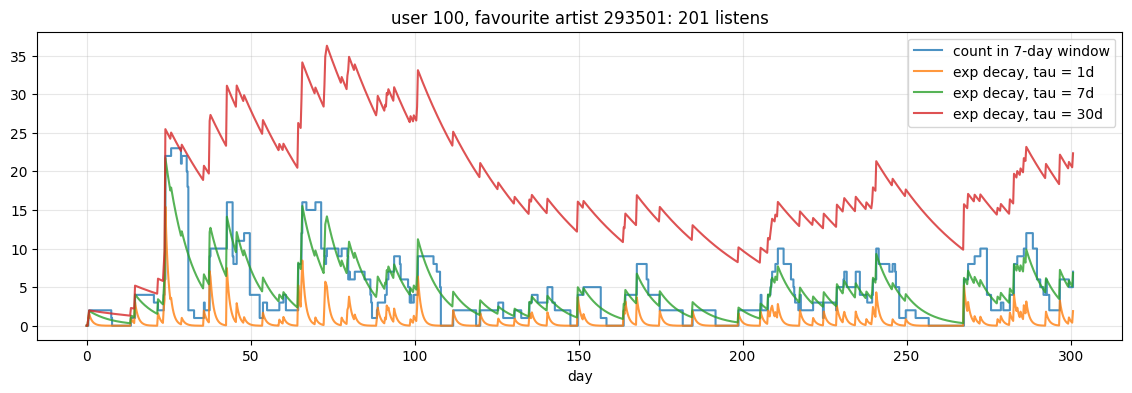

In [19]:
uid0 = users.filter(pl.col("listens").is_between(2500, 4000)).sort("uid")["uid"][0]
user_events = run(listens("uid", "artist_id", "timestamp").filter(pl.col("uid") == uid0))
fav_artist = user_events.drop_nulls().group_by("artist_id").len().sort("len", descending=True)["artist_id"][0]
ts = np.sort(user_events.filter(pl.col("artist_id") == fav_artist)["timestamp"].to_numpy().astype(np.float64))
grid = np.arange(0, T_END, DAY / 4, dtype=np.float64)
box = np.searchsorted(ts, grid, side="right") - np.searchsorted(ts, grid - 7 * DAY, side="right")

fig, ax = plt.subplots(figsize=(14, 4))
ax.step(grid / DAY, box, where="post", label="count in 7-day window", alpha=0.8)
for tau_days in [1, 7, 30]:
    tau = tau_days * DAY
    decay = np.array([np.exp(-(g - ts[ts <= g]) / tau).sum() for g in grid])
    ax.plot(grid / DAY, decay, label=f"exp decay, tau = {tau_days}d", alpha=0.8)
ax.set_xlabel("day")
ax.set_title(f"user {uid0}, favourite artist {fav_artist}: {len(ts)} listens")
ax.legend()
plt.show()

- Окно даёт "ступеньки": событие резко выпадает ровно через 7 дней. Затухание с тем же `tau` ведёт себя гладко и почти повторяет окно.
- Маленький `tau` реагирует на сегодняшний всплеск, большой хранит долгую привязанность. Набор значений `tau` - непрерывный аналог набора окон 1/7/30.
- Если сделать `tau` обучаемым параметром нейросети, вопрос "почему 7 дней, а не 10" решает градиент, а не перебор. Это ступени L1-L2 из `RESEARCH_DIRECTIONS.md`.

## 15. Итог: карта признаков

| Группа | Признаки | Откуда мотивация |
|---|---|---|
| Пользователь | активность по окнам, `listen_plus_rate`, доля скипов, `organic_share`, число уникальных треков и артистов, дни с последней активности | разделы 4, 6 |
| Трек | популярность по свежим окнам, сглаженный `listen_plus_rate`, доля скипов, длина, число слушателей, тренд (7д / 30д) | разделы 5, 7 |
| Пара: прямая связь | сколько раз слушал трек (по окнам или с затуханием), давность последнего прослушивания, доля дослушиваний, лайк или дизлайк на момент запроса | разделы 8, 9, 11 |
| Пара: косвенная связь | то же для артиста и альбома, доля и ранг артиста в истории, лайки артиста | разделы 8, 12 |
| Контекст | час суток, позиция в сессии, доля скипов в текущей сессии, источник (`is_organic`) | разделы 3, 10 |
| Коллаборативные | скор ItemKNN или ALS для пары, похожесть трека на последние прослушанные | раздел 13 |

**Ловушки утечек**
1. Все признаки считаются только по событиям строго раньше момента запроса, а при глобальном сплите ещё и с зазором.
2. Лайк, поставленный во время целевого прослушивания, нельзя использовать в признаках.
3. Статистики трека (например, `listen_plus_rate`) нельзя считать по всему датасету вместе с тестом.
4. Признаки сессии доступны только в постановке "ранжируем перед каждым показом".
5. Порог Listen+ и определение сессии фиксируем до экспериментов и не подбираем по тесту.

Подробный план бейзлайна в `BASELINE.md`, теория исследовательской части в `THEORY.md`.

## 16. Постановка A и разбиение на train / val / test

**Объект** - прослушивание, которое включил рекомендатель (`is_organic = 0`). **Метка** - дослушал ли (`listen_plus`). Органические прослушивания и лайки в таргет не идут, они только источник признаков. Почему так, объяснено в `BASELINE.md`, раздел 1.

Сначала проверим, есть ли недельный цикл. Если есть, val и test должны покрывать целую неделю, иначе метрика будет зависеть от того, какой день недели попал в тест.

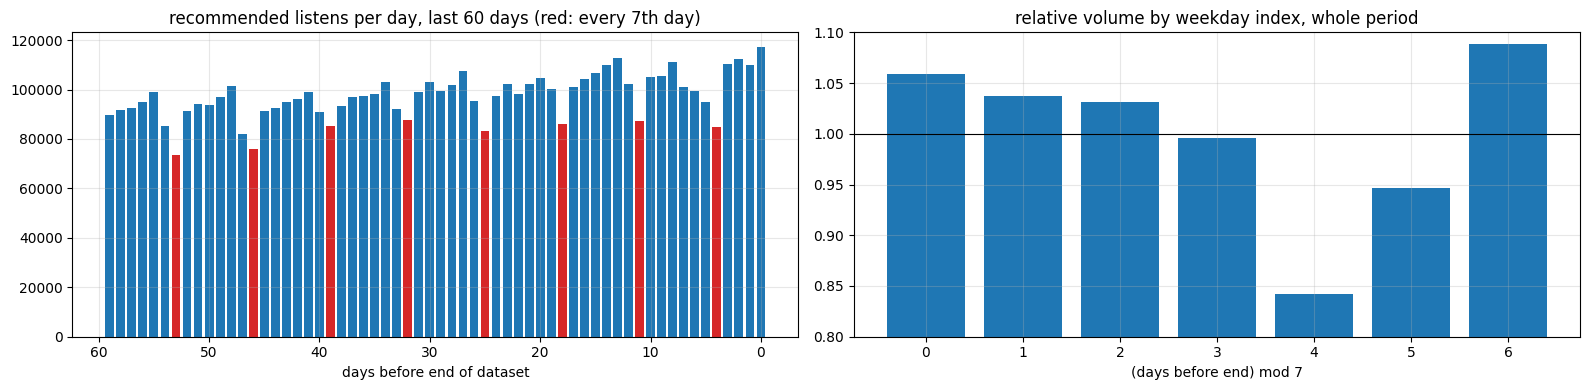

weekday_index,mean_n,relative_volume
u32,f64,f64
0,79557.452381,1.05926
1,77884.738095,1.036989
2,77447.119048,1.031162
3,74766.952381,0.995478
4,63244.238095,0.84206
5,71080.309524,0.946392
6,81765.47619,1.088659


In [20]:
rec_daily = run(
    listens("timestamp", "is_organic", "listen_plus")
    .filter(pl.col("is_organic") == 0)
    .group_by(((T_END - pl.col("timestamp")) // DAY).alias("days_before_end"))
    .agg(pl.len().alias("n"), pl.col("listen_plus").mean().alias("listen_plus_rate"))
).sort("days_before_end")

weekday = (
    rec_daily.filter(pl.col("days_before_end") < 294)
    .group_by((pl.col("days_before_end") % 7).alias("weekday_index"))
    .agg(pl.col("n").mean().alias("mean_n"))
    .with_columns((pl.col("mean_n") / pl.col("mean_n").mean()).alias("relative_volume"))
    .sort("weekday_index")
)

last = rec_daily.filter(pl.col("days_before_end") < 60)
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].bar(last["days_before_end"], last["n"], color=["tab:red" if d % 7 == 4 else "tab:blue" for d in last["days_before_end"]])
ax[0].invert_xaxis()
ax[0].set_xlabel("days before end of dataset")
ax[0].set_title("recommended listens per day, last 60 days (red: every 7th day)")
ax[1].bar(weekday["weekday_index"], weekday["relative_volume"])
ax[1].axhline(1, color="black", linewidth=0.8)
ax[1].set_ylim(0.8, 1.1)
ax[1].set_xlabel("(days before end) mod 7")
ax[1].set_title("relative volume by weekday index, whole period")
plt.tight_layout()
plt.show()
weekday

Цикл с периодом 7 дней виден по всему периоду: один день недели заметно тише остальных. Поэтому делаем так:

```
день от конца:   41 ............ 14 | 13 ...... 7 | 6 ....... 0
                 train (28 дней)    | val (7 дн) | test (7 дн)
```

Признаки для любого объекта считаются по **всей** истории строго до его момента. Ограничение в 28 дней касается только объектов с метками, на которых учится модель.

In [21]:
split = (
    pl.when(pl.col("days_before_end") < 7).then(pl.lit("3_test"))
    .when(pl.col("days_before_end") < 14).then(pl.lit("2_val"))
    .when(pl.col("days_before_end") < 42).then(pl.lit("1_train"))
    .otherwise(pl.lit("0_history_only"))
    .alias("split")
)
objects = (
    listens("uid", "timestamp", "is_organic", "listen_plus", "track_seen_n", "artist_seen_n")
    .filter(pl.col("is_organic") == 0)
    .with_columns(((T_END - pl.col("timestamp")) // DAY).alias("days_before_end"))
    .with_columns(split)
)
summary = run(
    objects.group_by("split").agg(
        pl.len().alias("objects"),
        pl.col("uid").n_unique().alias("users"),
        pl.col("listen_plus").mean().alias("positive_rate"),
        (pl.col("track_seen_n") > 0).mean().alias("repeat_track"),
        ((pl.col("track_seen_n") == 0) & (pl.col("artist_seen_n") > 0)).mean().alias("new_track_known_artist"),
        ((pl.col("track_seen_n") == 0) & ~(pl.col("artist_seen_n") > 0)).mean().alias("new_artist"),
    )
).sort("split")
display(summary)

users_by_split = run(objects.filter(pl.col("split") != "0_history_only").select("uid", "split").unique())
train_users = users_by_split.filter(pl.col("split") == "1_train").select("uid")
history_users = run(
    listens("uid", "timestamp").filter(pl.col("timestamp") < T_END - 14 * DAY).select("uid").unique()
)
for name in ["2_val", "3_test"]:
    part = users_by_split.filter(pl.col("split") == name).select("uid")
    in_train = part.join(train_users, on="uid", how="semi").height / part.height
    has_history = part.join(history_users, on="uid", how="semi").height / part.height
    print(f"{name}: {part.height} users, in train objects: {in_train:.1%}, have any history before val start: {has_history:.1%}")
del objects, users_by_split, train_users, history_users
rss()

split,objects,users,positive_rate,repeat_track,new_track_known_artist,new_artist
str,u32,u32,f64,f64,f64,f64
"""0_history_only""",18262704,8138,0.681203,0.615574,0.212232,0.172155
"""1_train""",2746414,7491,0.676934,0.6204,0.21863,0.160939
"""2_val""",725488,6283,0.693007,0.611752,0.224042,0.164187
"""3_test""",728949,6167,0.706534,0.619105,0.218701,0.162162


2_val: 6283 users, in train objects: 94.6%, have any history before val start: 100.0%
3_test: 6167 users, in train objects: 93.4%, have any history before val start: 100.0%
process memory: 0.32 GB


**Что это значит для задачи**
- Доля позитивов слегка растёт к концу датасета, а состав новизны во всех частях похож. Значит, разбиение не создаёт разных задач в train и test, есть только мягкий дрейф во времени. Это нормально и честно отражает продакшен.
- Почти все пользователи val и test есть в train, и почти у всех есть история до начала валидации. Задача холодного старта пользователей у нас практически отсутствует. В отчёте это стоит указать как ограничение.
- Объём train около 2.8M объектов, val и test примерно по 0.73M. CatBoost на таком объёме обучается на CPU за минуты.
- Дальше: `scripts/build_features.py` по плану из `BASELINE.md`.